In [1]:
#  acquire and inspect biological reference metadata
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen
import hashlib
import json
import pandas as pd

# Locate the existing project from the notebook working directory.
PROJECT_ROOT = next(
    (
        path for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "data/processed/acoustic_features_recording.csv").exists()
    ),
    None
)
assert PROJECT_ROOT is not None, "Run from inside the project directory."

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
metadata_dir = (
    PROJECT_ROOT / "data/raw/external"
    / "sapsucker_woods_7079380" / f"metadata_{stamp}"
)
metadata_dir.mkdir(parents=True, exist_ok=False)

base_url = "https://zenodo.org/records/7079380/files/"
filenames = [
    "annotations.csv",
    "species.csv",
    "recording_location.txt",
]

manifest = {
    "dataset": "Sapsucker Woods annotated soundscapes",
    "zenodo_record": "7079380",
    "source": "https://zenodo.org/records/7079380",
    "downloaded_utc": stamp,
    "purpose": "Metadata feasibility audit; no audio or models",
    "files": []
}

for filename in filenames:
    url = base_url + filename + "?download=1"
    request = Request(
        url, headers={"User-Agent": "SoundscapesBiodiversityResearch/1.0"}
    )

    with urlopen(request, timeout=90) as response:
        payload = response.read()

    assert payload, f"Empty download: {filename}"
    assert not payload.lstrip().lower().startswith(
        (b"<!doctype html", b"<html")
    ), f"Received HTML instead of metadata: {filename}"

    destination = metadata_dir / filename
    destination.write_bytes(payload)

    manifest["files"].append({
        "filename": filename,
        "url": url,
        "bytes": len(payload),
        "sha256": hashlib.sha256(payload).hexdigest()
    })
    print(f"Downloaded: {filename} ({len(payload):,} bytes)")

with open(metadata_dir / "download_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

# Infer delimiter for inspection; preserve identifiers and label codes as text.
annotations = pd.read_csv(
    metadata_dir / "annotations.csv",
    sep=None, engine="python", dtype=str
)
species_lookup = pd.read_csv(
    metadata_dir / "species.csv",
    sep=None, engine="python", dtype=str
)

for title, table in [
    ("ANNOTATIONS", annotations),
    ("SPECIES LOOKUP", species_lookup)
]:
    print(f"\n{title}")
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())
    print("\nFirst five rows:")
    print(table.head(5).to_string(index=False))
    print("\nMissing values by column:")
    print(table.isna().sum().to_string())
    print("Exact duplicate rows:", int(table.duplicated().sum()))

print("\nLOCATION DESCRIPTION")
print(
    (metadata_dir / "recording_location.txt")
    .read_text(encoding="utf-8-sig")
)

print("\nSaved:", metadata_dir)
print("No audio downloaded. No labels modified. No models fitted.")
print("Study A partitions and final test remain unchanged.")

Downloaded: annotations.csv (3,179,389 bytes)
Downloaded: species.csv (3,490 bytes)
Downloaded: recording_location.txt (78 bytes)

ANNOTATIONS
Shape: (53503, 6)
Columns: ['Filename', 'Start Time (s)', 'End Time (s)', 'Low Freq (Hz)', 'High Freq (Hz)', 'Species eBird Code']

First five rows:
                     Filename Start Time (s) End Time (s) Low Freq (Hz) High Freq (Hz) Species eBird Code
SSW_001_20170225_010000Z.flac           47.4         51.3             0           2647             cangoo
SSW_001_20170225_010000Z.flac           70.6        114.8           490           3529             cangoo
SSW_001_20170225_010000Z.flac          119.0        120.6             0           4509             cangoo
SSW_001_20170225_010000Z.flac          155.4        157.2             0           4019             cangoo
SSW_001_20170225_010000Z.flac          674.5        690.8           196           4019             cangoo

Missing values by column:
Filename              0
Start Time (s)       

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

metadata_dir = (
    PROJECT_ROOT / "data/raw/external/sapsucker_woods_7079380"
    / "metadata_20261030T224258610205Z"
)

annotations = pd.read_csv(
    metadata_dir / "annotations.csv", dtype=str
)
species_lookup = pd.read_csv(
    metadata_dir / "species.csv", dtype=str
)

a = annotations.copy()
s = species_lookup.copy()
code_col = "Species eBird Code"

print("A. TEXT AND LABEL INTEGRITY")
for name, table in [("annotations", a), ("species lookup", s)]:
    padded = sum(
        int(table[col].ne(table[col].str.strip()).sum())
        for col in table.columns
    )
    blank = sum(
        int(table[col].str.strip().eq("").sum())
        for col in table.columns
    )
    print(f"{name}: padded cells={padded}; blank cells={blank}")

assert s[code_col].is_unique, "Duplicate species lookup codes."
assert not a.isna().any().any()
assert not s.isna().any().any()

unmatched = sorted(set(a[code_col]) - set(s[code_col]))
unused = sorted(set(s[code_col]) - set(a[code_col]))

print("Annotation codes missing from lookup:", unmatched)
print("Lookup codes absent from annotations:", unused)
print("Distinct annotation codes:", a[code_col].nunique())

# Display possible unknown/non-species labels for review.
suspect = (
    ~s[code_col].str.fullmatch(r"[a-z0-9]+", na=False)
    | s.astype(str).apply(
        lambda col: col.str.contains(
            r"unknown|unident|uncertain|\?",
            case=False, regex=True, na=False
        )
    ).any(axis=1)
)
print("\nPossible unidentified/non-species lookup entries:")
print(s.loc[suspect].to_string(index=False))

print("\nB. NUMERICAL ANNOTATION CHECKS")
numeric_cols = [
    "Start Time (s)", "End Time (s)",
    "Low Freq (Hz)", "High Freq (Hz)"
]
numeric = a[numeric_cols].apply(pd.to_numeric, errors="coerce")
finite = pd.Series(
    np.isfinite(numeric.to_numpy()).all(axis=1), index=a.index
)

start = numeric["Start Time (s)"]
end = numeric["End Time (s)"]
low = numeric["Low Freq (Hz)"]
high = numeric["High Freq (Hz)"]

checks = pd.DataFrame({
    "non_numeric_or_nonfinite": ~finite,
    "negative_start": start < 0,
    "end_not_after_start": end <= start,
    "end_after_documented_hour": end > 3600,
    "negative_low_frequency": low < 0,
    "high_not_above_low": high <= low,
    "high_above_32kHz_nyquist": high > 16000
})
print(checks.sum().to_string())

bad = checks.any(axis=1)
if bad.any():
    print("\nFirst problematic rows — inspection only:")
    print(a.loc[bad].head(10).to_string(index=False))

print("\nAnnotation duration (seconds):")
print((end - start).describe().round(3).to_string())

print("\nC. RECORDING AND TEMPORAL SUPPORT")
recordings = pd.DataFrame({
    "Filename": sorted(a["Filename"].unique())
})
parts = recordings["Filename"].str.extract(
    r"^SSW_(?P<file_id>\d+)_(?P<date>\d{8})_"
    r"(?P<time>\d{6})Z\.flac$"
)

recordings["file_id"] = parts["file_id"]
recordings["timestamp_utc"] = pd.to_datetime(
    parts["date"] + parts["time"],
    format="%Y%m%d%H%M%S", utc=True, errors="coerce"
)
print("Annotated recording files:", len(recordings))
print("Filename/timestamp parsing failures:",
      int(recordings["timestamp_utc"].isna().sum()))
assert recordings["timestamp_utc"].notna().all(), (
    "Inspect filename parsing before continuing."
)

recordings["timestamp_local"] = (
    recordings["timestamp_utc"].dt.tz_convert("America/New_York")
)
recordings["date_utc"] = recordings["timestamp_utc"].dt.strftime("%Y-%m-%d")
recordings["date_local"] = recordings["timestamp_local"].dt.strftime("%Y-%m-%d")
recordings["month_local"] = recordings["timestamp_local"].dt.strftime("%Y-%m")
recordings["hour_local"] = recordings["timestamp_local"].dt.hour

print("UTC range:",
      recordings["timestamp_utc"].min(),
      "to", recordings["timestamp_utc"].max())
print("Distinct UTC dates:", recordings["date_utc"].nunique())
print("Distinct local dates:", recordings["date_local"].nunique())

print("\nRecording counts by local month:")
print(recordings.groupby("month_local").size().to_string())

print("\nRecording counts by UTC date:")
print(recordings.groupby("date_utc").size().to_string())

print("\nRecording counts by local hour:")
print(
    recordings.groupby("hour_local").size()
    .reindex(range(24), fill_value=0).to_string()
)

print("\nD. LABEL SUPPORT")
label_support = (
    a.groupby(code_col)
    .agg(
        annotation_boxes=("Filename", "size"),
        recordings=("Filename", "nunique")
    )
    .reset_index()
    .merge(s, on=code_col, how="left", validate="one_to_one")
    .sort_values("annotation_boxes", ascending=False)
)
print(label_support.head(15).to_string(index=False))

print("\nPossible unidentified-label support:")
print(
    label_support.loc[
        label_support[code_col].isin(s.loc[suspect, code_col])
    ].to_string(index=False)
)

print("\nNo annotations removed, intervals defined, or splits created.")
print("Counts describe annotation boxes, not individual birds.")
print("Audio and pretrained-model evaluation remain pending.")

A. TEXT AND LABEL INTEGRITY
annotations: padded cells=0; blank cells=0
species lookup: padded cells=0; blank cells=0
Annotation codes missing from lookup: []
Lookup codes absent from annotations: []
Distinct annotation codes: 82

Possible unidentified/non-species lookup entries:
Species eBird Code Scientific Name Common Name
              ????         unknown     unknown

B. NUMERICAL ANNOTATION CHECKS
non_numeric_or_nonfinite     0
negative_start               0
end_not_after_start          9
end_after_documented_hour    0
negative_low_frequency       0
high_not_above_low           8
high_above_32kHz_nyquist     0

First problematic rows — inspection only:
                     Filename Start Time (s) End Time (s) Low Freq (Hz) High Freq (Hz) Species eBird Code
SSW_027_20170304_170010Z.flac         1215.4       1215.4          8536           8536             comgra
SSW_027_20170304_170010Z.flac         1221.3       1221.3          6829           6829               ????
SSW_029_20170304

In [3]:
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd

a = annotations.copy()
code_col = "Species eBird Code"

for col in [
    "Start Time (s)", "End Time (s)",
    "Low Freq (Hz)", "High Freq (Hz)"
]:
    a[col] = pd.to_numeric(a[col], errors="raise")

assert np.isfinite(a.select_dtypes(include="number").to_numpy()).all()
assert a["Start Time (s)"].ge(0).all()
assert a["End Time (s)"].le(3600).all()

a["source_row"] = np.arange(len(a))
a["positive_duration"] = a["End Time (s)"] > a["Start Time (s)"]
a["valid_frequency_box"] = a["High Freq (Hz)"] > a["Low Freq (Hz)"]
a["unknown_label"] = a[code_col].eq("????")

# Do not silently reinterpret reversed time intervals.
assert a["End Time (s)"].ge(a["Start Time (s)"]).all()

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
reference_dir = (
    PROJECT_ROOT / "data/processed/biodiversity"
    / f"ssw_reference_{stamp}"
)
reference_dir.mkdir(parents=True, exist_ok=False)

interval_rows = []
presence_rows = []

for filename, boxes in a.groupby("Filename", sort=True):
    # Filename dates identify provisional sampling-session groups.
    parts = filename.removesuffix(".flac").split("_")
    timestamp = pd.to_datetime(
        parts[2] + parts[3],
        format="%Y%m%d%H%M%SZ", utc=True
    )
    session = timestamp.strftime("%Y-%m-%d")

    valid = boxes.loc[boxes["positive_duration"]]
    points = boxes.loc[~boxes["positive_duration"]]

    for minute in range(60):
        start = minute * 60
        end = start + 60
        interval_id = f"{filename.removesuffix('.flac')}_m{minute:02d}"

        # Half-open interval [start, end); require positive overlap.
        overlap = valid.loc[
            valid["Start Time (s)"].lt(end)
            & valid["End Time (s)"].gt(start)
        ]
        named = overlap.loc[~overlap["unknown_label"]]
        species = sorted(named[code_col].unique())

        # Flag zero-duration points without manufacturing call durations.
        # A point exactly at 3600 seconds flags the final interval.
        point_times = points["Start Time (s)"]
        point_here = points.loc[
            point_times.ge(start)
            & (
                point_times.lt(end)
                | ((minute == 59) & point_times.eq(3600))
            )
        ]

        interval_rows.append({
            "interval_id": interval_id,
            "Filename": filename,
            "session_utc": session,
            "minute_index": minute,
            "start_seconds": start,
            "end_seconds": end,
            "annotated_named_richness": len(species),
            "named_annotation_boxes": len(named),
            "unknown_annotation_boxes": int(
                overlap["unknown_label"].sum()
            ),
            "has_unknown_annotation": bool(
                overlap["unknown_label"].any()
            ),
            "has_any_positive_duration_annotation": len(overlap) > 0,
            "zero_duration_points": len(point_here),
            "named_zero_duration_points": int(
                (~point_here["unknown_label"]).sum()
            ),
            "invalid_frequency_boxes": int(
                (~overlap["valid_frequency_box"]).sum()
            )
        })

        for code in species:
            presence_rows.append({
                "interval_id": interval_id,
                "Species eBird Code": code
            })

interval_reference = pd.DataFrame(interval_rows)
species_presence = pd.DataFrame(presence_rows)

assert interval_reference["interval_id"].is_unique
assert len(interval_reference) == a["Filename"].nunique() * 60
assert interval_reference.groupby("Filename").size().eq(60).all()
assert not species_presence.duplicated().any()
assert not species_presence["Species eBird Code"].eq("????").any()

# Verify that the species-presence table reproduces interval richness.
reconstructed = (
    species_presence.groupby("interval_id").size()
    .reindex(interval_reference["interval_id"], fill_value=0)
    .to_numpy()
)
assert np.array_equal(
    reconstructed,
    interval_reference["annotated_named_richness"].to_numpy()
)

policy = {
    "outcome": "Annotated audible named-species richness",
    "interval_seconds": 60,
    "interval_rule": "Half-open intervals; any positive annotation overlap",
    "duration_basis": (
        "Documented one-hour recordings; actual audio duration not yet verified"
    ),
    "unknown_labels": "Tracked separately; excluded from named-species richness",
    "zero_duration_boxes": (
        "Retained in audit; excluded from primary overlap; affected intervals flagged"
    ),
    "invalid_frequency_boxes": (
        "Flagged; positive-duration species/time annotations remain eligible"
    ),
    "grouping_candidate": "UTC recording date; provisional sampling session",
    "limitations": [
        "No annotation does not establish biological absence.",
        "Richness describes annotated audible species, not total site richness.",
        "Source collection excluded bird-free recordings.",
        "No recorder-level or unseen-site independence established.",
        "Intervals from the same recording/session must remain together."
    ],
    "splits_created": False,
    "audio_verified": False
}

interval_reference.to_csv(
    reference_dir / "interval_reference.csv", index=False
)
species_presence.to_csv(
    reference_dir / "interval_species_presence.csv", index=False
)
a.loc[
    ~a["positive_duration"] | ~a["valid_frequency_box"]
].to_csv(reference_dir / "annotation_exceptions.csv", index=False)

with open(reference_dir / "reference_policy.json", "w", encoding="utf-8") as f:
    json.dump(policy, f, indent=2)

print("BIOLOGICAL REFERENCE SUPPORT")
print("Recordings:", interval_reference["Filename"].nunique())
print("Provisional sessions:", interval_reference["session_utc"].nunique())
print("One-minute intervals:", len(interval_reference))
print(
    "Intervals with no positive-duration annotation:",
    int((~interval_reference["has_any_positive_duration_annotation"]).sum())
)
print(
    "Intervals with unknown annotations:",
    int(interval_reference["has_unknown_annotation"].sum())
)
print(
    "Intervals affected by zero-duration points:",
    int(interval_reference["zero_duration_points"].gt(0).sum())
)

print("\nANNOTATED NAMED-SPECIES RICHNESS")
print(
    interval_reference["annotated_named_richness"]
    .value_counts().sort_index().rename("intervals").to_string()
)

print("\nSESSION SUPPORT")
print(
    interval_reference.groupby("session_utc").agg(
        recordings=("Filename", "nunique"),
        intervals=("interval_id", "size"),
        mean_annotated_richness=("annotated_named_richness", "mean"),
        intervals_with_unknown=("has_unknown_annotation", "sum")
    ).round(3).to_string()
)

print("\nSaved:", reference_dir)
print("Source files unchanged. No audio downloaded or splits created.")

BIOLOGICAL REFERENCE SUPPORT
Recordings: 285
Provisional sessions: 21
One-minute intervals: 17100
Intervals with no positive-duration annotation: 7970
Intervals with unknown annotations: 1515
Intervals affected by zero-duration points: 8

ANNOTATED NAMED-SPECIES RICHNESS
annotated_named_richness
0     8255
1     3797
2     2262
3     1415
4      790
5      346
6      141
7       52
8       24
9       10
10       3
11       5

SESSION SUPPORT
             recordings  intervals  mean_annotated_richness  intervals_with_unknown
session_utc                                                                        
2017-02-25           17       1020                    0.781                      39
2017-03-04           14        840                    0.381                      67
2017-03-11           17       1020                    0.386                       5
2017-03-18            1         60                    0.017                       0
2017-03-25           16        960                

In [4]:
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd

reference_dir = (
    PROJECT_ROOT / "data/processed/biodiversity"
    / "ssw_reference_20261030T225304854848Z"
)

reference = pd.read_csv(reference_dir / "interval_reference.csv")

# Selection uses filenames and timestamps only—not biological outcomes.
files = pd.DataFrame({
    "Filename": sorted(reference["Filename"].unique())
})
parts = files["Filename"].str.extract(
    r"^SSW_(?P<file_id>\d+)_(?P<date>\d{8})_"
    r"(?P<time>\d{6})Z\.flac$"
)
files["timestamp_utc"] = pd.to_datetime(
    parts["date"] + parts["time"],
    format="%Y%m%d%H%M%S", utc=True, errors="raise"
)
files["session_utc"] = files["timestamp_utc"].dt.strftime("%Y-%m-%d")
files["month_utc"] = files["timestamp_utc"].dt.strftime("%Y-%m")
files["timestamp_local"] = (
    files["timestamp_utc"].dt.tz_convert("America/New_York")
)

seed = 42
rng = np.random.default_rng(seed)
selected = []

for month, monthly_files in files.groupby("month_utc", sort=True):
    sessions = sorted(monthly_files["session_utc"].unique())
    chosen_session = str(rng.choice(sessions))

    candidates = monthly_files.loc[
        monthly_files["session_utc"].eq(chosen_session)
    ].sort_values("Filename").reset_index(drop=True)

    chosen = candidates.iloc[int(rng.integers(len(candidates)))]
    selected.append({
        "Filename": chosen["Filename"],
        "session_utc": chosen_session,
        "month_utc": month,
        "timestamp_utc": chosen["timestamp_utc"].isoformat(),
        "timestamp_local": chosen["timestamp_local"].isoformat(),
        "candidate_sessions_in_month": len(sessions),
        "candidate_files_in_session": len(candidates),
        "selection_seed": seed,
        "purpose": "engineering_pilot",
        "documented_duration_seconds": 3600
    })

pilot_manifest = pd.DataFrame(selected)
assert len(pilot_manifest) == 7
assert pilot_manifest["Filename"].is_unique
assert pilot_manifest["session_utc"].is_unique

# Entire selected sessions—not just selected files—are development-reserved.
session_roles = (
    files[["session_utc", "month_utc"]]
    .drop_duplicates()
    .sort_values("session_utc")
)
session_roles["role"] = np.where(
    session_roles["session_utc"].isin(pilot_manifest["session_utc"]),
    "development_reserved_pilot_session",
    "unassigned"
)

# Attach reference outcomes only AFTER selection is fixed.
pilot_reference = reference.loc[
    reference["Filename"].isin(pilot_manifest["Filename"])
].copy()
assert len(pilot_reference) == 420
assert pilot_reference.groupby("Filename").size().eq(60).all()

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
pilot_dir = (
    PROJECT_ROOT / "data/processed/biodiversity"
    / f"ssw_pilot_{stamp}"
)
pilot_dir.mkdir(parents=True, exist_ok=False)

pilot_manifest.to_csv(pilot_dir / "pilot_manifest.csv", index=False)
pilot_reference.to_csv(pilot_dir / "pilot_interval_reference.csv", index=False)
session_roles.to_csv(pilot_dir / "session_roles.csv", index=False)

protocol = {
    "purpose": "Engineering feasibility, not final biodiversity evaluation",
    "seed": seed,
    "selection": (
        "One UTC session uniformly sampled per UTC month; then one "
        "recording uniformly sampled within that session."
    ),
    "outcomes_used_for_selection": False,
    "interval_selection": "All 60 consecutive one-minute intervals per file",
    "pilot_recordings": 7,
    "documented_audio_hours": 7,
    "actual_duration_verified": False,
    "evaluation_policy": (
        "Pilot sessions reserved for development; remaining sessions "
        "unassigned. No final evaluation split created."
    ),
    "limitations": [
        "Small feasibility sample; not a representative ecological survey.",
        "Unequal recording inclusion probabilities from two-stage sampling.",
        "Do not replace a selected recording because it is quiet or difficult."
    ],
    "source_reference": str(reference_dir),
    "audio_downloaded": False
}
with open(pilot_dir / "pilot_protocol.json", "w", encoding="utf-8") as f:
    json.dump(protocol, f, indent=2)

print("FIXED AUDIO PILOT")
print(
    pilot_manifest[
        ["Filename", "session_utc", "timestamp_local"]
    ].to_string(index=False)
)
print("\nRecordings:", len(pilot_manifest))
print("One-minute intervals:", len(pilot_reference))
print("\nSESSION ROLES")
print(session_roles["role"].value_counts().to_string())
print("\nSaved:", pilot_dir)
print("No audio downloaded. No final evaluation split created.")

FIXED AUDIO PILOT
                     Filename session_utc           timestamp_local
SSW_002_20170225_020001Z.flac  2017-02-25 2017-02-24T21:00:01-05:00
SSW_060_20170325_140009Z.flac  2017-03-25 2017-03-25T10:00:09-04:00
SSW_087_20170408_140008Z.flac  2017-04-08 2017-04-08T10:00:08-04:00
SSW_158_20170520_050007Z.flac  2017-05-20 2017-05-20T01:00:07-04:00
SSW_201_20170617_090007Z.flac  2017-06-17 2017-06-17T05:00:07-04:00
SSW_221_20170701_140009Z.flac  2017-07-01 2017-07-01T10:00:09-04:00
SSW_283_20170826_170022Z.flac  2017-08-26 2017-08-26T13:00:22-04:00

Recordings: 7
One-minute intervals: 420

SESSION ROLES
role
unassigned                            14
development_reserved_pilot_session     7

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\biodiversity\ssw_pilot_20261030T225429974265Z
No audio downloaded. No final evaluation split created.


In [5]:
from urllib.request import Request, urlopen
import json

pilot_dir = (
    PROJECT_ROOT / "data/processed/biodiversity"
    / "ssw_pilot_20261030T225429974265Z"
)

archive_url = (
    "https://zenodo.org/records/7079380/files/"
    "soundscape_data.zip?download=1"
)
tail_bytes = 65557  # Maximum ordinary ZIP end-directory search length.

request = Request(
    archive_url,
    headers={
        "Range": f"bytes=-{tail_bytes}",
        "Accept-Encoding": "identity",
        "User-Agent": "SoundscapesBiodiversityResearch/1.0"
    }
)

with urlopen(request, timeout=90) as response:
    status = response.status
    content_range = response.headers.get("Content-Range")
    content_length = response.headers.get("Content-Length")
    encoding = response.headers.get("Content-Encoding")

    print("HTTP status:", status)
    print("Content-Range:", content_range)
    print("Content-Length:", content_length)
    print("Content-Encoding:", encoding)

    if status == 206:
        payload = response.read(tail_bytes + 1)
        assert len(payload) <= tail_bytes, "Oversized partial response."
        assert content_range, "Missing range metadata."
        (pilot_dir / "archive_tail.bin").write_bytes(payload)

        print("Received bytes:", len(payload))
        print("ZIP end-directory signature present:",
              b"PK\x05\x06" in payload)
        print("ZIP64 locator present:", b"PK\x06\x07" in payload)
        print("Partial retrieval supported; tail saved.")
    else:
        print("Partial retrieval not confirmed.")
        print("Response closed without reading the archive body.")

probe = {
    "url": archive_url,
    "http_status": status,
    "content_range": content_range,
    "content_length": content_length,
    "content_encoding": encoding,
    "requested_tail_bytes": tail_bytes
}
with open(pilot_dir / "archive_access_probe.json", "w", encoding="utf-8") as f:
    json.dump(probe, f, indent=2)

print("No audio extracted. Pilot selection unchanged.")

HTTP status: 206
Content-Range: bytes 27762432288-27762497844/27762497845
Content-Length: 65557
Content-Encoding: None
Received bytes: 65557
ZIP end-directory signature present: True
ZIP64 locator present: True
Partial retrieval supported; tail saved.
No audio extracted. Pilot selection unchanged.


In [6]:
import io
import json
import re
import zipfile
from pathlib import PurePosixPath
from urllib.request import Request, urlopen
import pandas as pd

with open(pilot_dir / "archive_access_probe.json", encoding="utf-8") as f:
    probe = json.load(f)

archive_url = probe["url"]
match = re.fullmatch(
    r"bytes (\d+)-(\d+)/(\d+)", probe["content_range"]
)
assert match, "Unexpected Content-Range."
tail_start, tail_end, archive_size = map(int, match.groups())
tail = (pilot_dir / "archive_tail.bin").read_bytes()
assert len(tail) == tail_end - tail_start + 1

class RemoteZipDirectory(io.RawIOBase):
    """Seekable HTTP reader with a strict metadata-read size limit."""

    def __init__(self):
        super().__init__()
        self.position = 0
        self.downloaded_bytes = 0

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.position

    def seek(self, offset, whence=io.SEEK_SET):
        if whence == io.SEEK_SET:
            position = offset
        elif whence == io.SEEK_CUR:
            position = self.position + offset
        elif whence == io.SEEK_END:
            position = archive_size + offset
        else:
            raise ValueError("Invalid seek mode.")
        if position < 0:
            raise ValueError("Negative seek.")
        self.position = position
        return position

    def read(self, size=-1):
        if size is None or size < 0:
            size = max(0, archive_size - self.position)
        size = min(size, max(0, archive_size - self.position))
        if size == 0:
            return b""
        if size > 8 * 1024**2:
            raise RuntimeError(
                "Read exceeds 8 MiB metadata limit; stopped safely."
            )

        start = self.position
        end = start + size - 1

        if start >= tail_start and end <= tail_end:
            data = tail[start - tail_start:end - tail_start + 1]
        else:
            request = Request(
                archive_url,
                headers={
                    "Range": f"bytes={start}-{end}",
                    "Accept-Encoding": "identity",
                    "User-Agent": "SoundscapesBiodiversityResearch/1.0"
                }
            )
            with urlopen(request, timeout=90) as response:
                assert response.status == 206, "Range request ignored."
                expected = f"bytes {start}-{end}/{archive_size}"
                assert response.headers.get("Content-Range") == expected
                assert response.headers.get("Content-Encoding") in (
                    None, "identity"
                )
                data = response.read(size + 1)
                assert len(data) == size, "Unexpected response length."
            self.downloaded_bytes += len(data)

        self.position += len(data)
        return data

pilot = pd.read_csv(pilot_dir / "pilot_manifest.csv")
rows = []

with RemoteZipDirectory() as remote:
    with zipfile.ZipFile(remote) as archive:
        members = [info for info in archive.infolist() if not info.is_dir()]
        print("Archive file entries:", len(members))

        for filename in pilot["Filename"]:
            matches = [
                info for info in members
                if PurePosixPath(info.filename).name == filename
            ]
            assert len(matches) == 1, (
                f"Expected one exact match for {filename}; got {len(matches)}."
            )
            info = matches[0]
            assert not (info.flag_bits & 1), "Encrypted member encountered."

            rows.append({
                "Filename": filename,
                "archive_member": info.filename,
                "compressed_bytes": info.compress_size,
                "uncompressed_bytes": info.file_size,
                "compression_method": info.compress_type,
                "header_offset": info.header_offset,
                "crc32_hex": f"{info.CRC:08x}"
            })

    print("Additional directory bytes downloaded:",
          remote.downloaded_bytes)

members_manifest = pd.DataFrame(rows)
members_manifest.to_csv(
    pilot_dir / "pilot_archive_members.csv", index=False
)

display_table = members_manifest[["Filename", "compression_method"]].copy()
display_table["download_MiB"] = (
    members_manifest["compressed_bytes"] / 1024**2
).round(2)
display_table["extracted_MiB"] = (
    members_manifest["uncompressed_bytes"] / 1024**2
).round(2)

print("\nSELECTED AUDIO FILES")
print(display_table.to_string(index=False))
print(
    "\nTotal compressed download: "
    f"{members_manifest['compressed_bytes'].sum() / 1024**3:.3f} GiB"
)
print(
    "Total extracted audio: "
    f"{members_manifest['uncompressed_bytes'].sum() / 1024**3:.3f} GiB"
)
print("\nMember manifest saved. No audio downloaded or extracted.")

Archive file entries: 285
Additional directory bytes downloaded: 0

SELECTED AUDIO FILES
                     Filename  compression_method  download_MiB  extracted_MiB
SSW_002_20170225_020001Z.flac                   8         85.88          85.95
SSW_060_20170325_140009Z.flac                   8         89.15          89.20
SSW_087_20170408_140008Z.flac                   8         94.85          94.84
SSW_158_20170520_050007Z.flac                   8         84.42          84.47
SSW_201_20170617_090007Z.flac                   8         92.55          92.58
SSW_221_20170701_140009Z.flac                   8         90.57          90.62
SSW_283_20170826_170022Z.flac                   8         89.68          89.78

Total compressed download: 0.612 GiB
Total extracted audio: 0.613 GiB

Member manifest saved. No audio downloaded or extracted.


In [8]:
import hashlib
import json
import struct
import zlib
from datetime import datetime, timezone
from urllib.request import Request, urlopen
import pandas as pd

members = pd.read_csv(
    pilot_dir / "pilot_archive_members.csv",
    dtype={"crc32_hex": str}
)
with open(pilot_dir / "archive_access_probe.json", encoding="utf-8") as f:
    probe = json.load(f)

archive_url = probe["url"]
archive_size = int(probe["content_range"].split("/")[-1])

audio_dir = (
    PROJECT_ROOT / "data/raw/external"
    / "sapsucker_woods_7079380/audio"
)
audio_dir.mkdir(parents=True, exist_ok=True)

def open_range(start, end):
    request = Request(
        archive_url,
        headers={
            "Range": f"bytes={start}-{end}",
            "Accept-Encoding": "identity",
            "User-Agent": "SoundscapesBiodiversityResearch/1.0"
        }
    )
    response = urlopen(request, timeout=120)
    expected = f"bytes {start}-{end}/{archive_size}"
    if (
        response.status != 206
        or response.headers.get("Content-Range") != expected
        or response.headers.get("Content-Encoding") not in (None, "identity")
    ):
        response.close()
        raise RuntimeError("Unexpected HTTP range response; download stopped.")
    return response

def read_range(start, length):
    with open_range(start, start + length - 1) as response:
        data = response.read(length + 1)
    assert len(data) == length, "Incomplete range."
    return data

def fingerprint(path):
    size, crc = 0, 0
    sha = hashlib.sha256()
    with path.open("rb") as handle:
        while chunk := handle.read(1024**2):
            size += len(chunk)
            crc = zlib.crc32(chunk, crc)
            sha.update(chunk)
    return size, f"{crc & 0xffffffff:08x}", sha.hexdigest()

records = []

for member in members.to_dict("records"):
    filename = member["Filename"]
    assert "/" not in filename and "\\" not in filename
    destination = audio_dir / filename
    expected_size = int(member["uncompressed_bytes"])
    expected_crc = member["crc32_hex"].lower().zfill(8)

    if destination.exists():
        size, crc, sha256 = fingerprint(destination)
        assert size == expected_size and crc == expected_crc, (
            f"Existing file failed verification: {filename}. "
            "File preserved; inspect before continuing."
        )
        status = "existing_verified"
        print("Verified existing:", filename)

    else:
        print("Downloading:", filename, flush=True)
        offset = int(member["header_offset"])

        # ZIP local header: signature, version, flags, method, timestamps,
        # CRC, compressed/uncompressed sizes, filename/extra-field lengths.
        header = struct.unpack("<4s5H3I2H", read_range(offset, 30))
        assert header[0] == b"PK\x03\x04"
        flags, method = header[2], header[3]
        assert not flags & 1, "Encrypted member."
        assert method == int(member["compression_method"]) == 8

        name_length, extra_length = header[-2:]
        local_name = read_range(offset + 30, name_length).decode(
            "utf-8" if flags & 0x800 else "cp437"
        )
        assert local_name == member["archive_member"]

        data_start = offset + 30 + name_length + extra_length
        compressed_size = int(member["compressed_bytes"])
        data_end = data_start + compressed_size - 1
        assert data_end < archive_size

        temporary = destination.with_suffix(".flac.part")
        decoder = zlib.decompressobj(-zlib.MAX_WBITS)
        received = 0
        extracted = 0

        # A failed attempt leaves a .part file; rerunning restarts that file.
        with open_range(data_start, data_end) as response:
            with temporary.open("wb") as output:
                while received < compressed_size:
                    chunk = response.read(
                        min(1024**2, compressed_size - received)
                    )
                    if not chunk:
                        raise IOError("Download ended prematurely.")
                    received += len(chunk)
                    decoded = decoder.decompress(chunk)
                    extracted += len(decoded)
                    assert extracted <= expected_size
                    output.write(decoded)

                remainder = decoder.flush()
                extracted += len(remainder)
                assert extracted <= expected_size
                output.write(remainder)

        assert decoder.eof, "Incomplete compressed stream."
        assert not decoder.unused_data, "Unexpected trailing compressed data."
        assert received == compressed_size

        size, crc, sha256 = fingerprint(temporary)
        assert size == expected_size, "Extracted size mismatch."
        assert crc == expected_crc, "ZIP CRC mismatch."

        # Rename only after verification; never overwrite an existing FLAC.
        temporary.rename(destination)
        status = "downloaded_verified"
        print("CRC and size verified:", filename, flush=True)

    records.append({
        "Filename": filename,
        "local_path": str(destination),
        "archive_member": member["archive_member"],
        "bytes": size,
        "crc32": crc,
        "sha256": sha256,
        "status": status,
        "verified_utc": datetime.now(timezone.utc).isoformat()
    })
    pd.DataFrame(records).to_csv(
        pilot_dir / "audio_verification.csv", index=False
    )

print("\nPILOT AUDIO VERIFIED")
print(pd.DataFrame(records)[["Filename", "bytes", "status"]].to_string(index=False))
print("\nAudio directory:", audio_dir)
print("No resampling, feature extraction, or model inference performed.")

Downloading: SSW_002_20170225_020001Z.flac


CRC and size verified: SSW_002_20170225_020001Z.flac
Downloading: SSW_060_20170325_140009Z.flac
CRC and size verified: SSW_060_20170325_140009Z.flac
Downloading: SSW_087_20170408_140008Z.flac
CRC and size verified: SSW_087_20170408_140008Z.flac
Downloading: SSW_158_20170520_050007Z.flac
CRC and size verified: SSW_158_20170520_050007Z.flac
Downloading: SSW_201_20170617_090007Z.flac
CRC and size verified: SSW_201_20170617_090007Z.flac
Downloading: SSW_221_20170701_140009Z.flac
CRC and size verified: SSW_221_20170701_140009Z.flac
Downloading: SSW_283_20170826_170022Z.flac
CRC and size verified: SSW_283_20170826_170022Z.flac

PILOT AUDIO VERIFIED
                     Filename    bytes              status
SSW_002_20170225_020001Z.flac 90120320 downloaded_verified
SSW_060_20170325_140009Z.flac 93538139 downloaded_verified
SSW_087_20170408_140008Z.flac 99449448 downloaded_verified
SSW_158_20170520_050007Z.flac 88574759 downloaded_verified
SSW_201_20170617_090007Z.flac 97077544 downloaded_veri

In [9]:
import numpy as np
import pandas as pd
import soundfile as sf

verification = pd.read_csv(pilot_dir / "audio_verification.csv")
pilot_reference = pd.read_csv(pilot_dir / "pilot_interval_reference.csv")

annotation_table = pd.read_csv(
    metadata_dir / "annotations.csv", dtype=str
)
for column in ["Start Time (s)", "End Time (s)"]:
    annotation_table[column] = pd.to_numeric(
        annotation_table[column], errors="raise"
    )

rows = []

for record in verification.to_dict("records"):
    filename = record["Filename"]
    path = audio_dir / filename
    labels = annotation_table.loc[
        annotation_table["Filename"].eq(filename)
    ]
    intervals = pilot_reference.loc[
        pilot_reference["Filename"].eq(filename)
    ]
    assert len(labels) > 0
    assert len(intervals) == 60

    with sf.SoundFile(path) as audio:
        sample_rate = audio.samplerate
        frames = audio.frames
        channels = audio.channels
        duration = frames / sample_rate

        # Three diagnostic excerpts; not a whole-file quality assessment.
        excerpt_frames = min(5 * sample_rate, frames)
        starts = sorted(set([
            0,
            max(0, (frames - excerpt_frames) // 2),
            max(0, frames - excerpt_frames)
        ]))
        excerpts = []
        for start in starts:
            audio.seek(start)
            excerpt = audio.read(
                excerpt_frames, dtype="float32", always_2d=True
            )
            assert len(excerpt) == excerpt_frames
            excerpts.append(excerpt)

        samples = np.concatenate(excerpts, axis=0)
        finite = bool(np.isfinite(samples).all())

        tolerance = 1 / sample_rate
        invalid_times = (
            labels["Start Time (s)"].lt(0)
            | labels["End Time (s)"].lt(labels["Start Time (s)"])
            | labels["End Time (s)"].gt(duration + tolerance)
        )
        covered_intervals = intervals["end_seconds"].le(
            duration + tolerance
        )

        rows.append({
            "Filename": filename,
            "sample_rate": sample_rate,
            "channels": channels,
            "format": audio.format,
            "subtype": audio.subtype,
            "frames": frames,
            "duration_seconds": duration,
            "difference_from_3600_seconds": duration - 3600,
            "annotation_boxes": len(labels),
            "annotations_outside_time_bounds": int(invalid_times.sum()),
            "fully_covered_minutes": int(covered_intervals.sum()),
            "excerpt_samples_finite": finite,
            "excerpt_peak": float(np.max(np.abs(samples))),
            "excerpt_rms": float(
                np.sqrt(np.mean(samples.astype(np.float64) ** 2))
            ),
            "excerpt_fraction_abs_ge_0_999": float(
                np.mean(np.abs(samples) >= 0.999)
            )
        })

audio_audit = pd.DataFrame(rows)
audio_audit.to_csv(pilot_dir / "audio_structure_audit.csv", index=False)

print("AUDIO STRUCTURE")
print(
    audio_audit[[
        "Filename", "sample_rate", "channels", "subtype",
        "duration_seconds", "difference_from_3600_seconds",
        "annotations_outside_time_bounds", "fully_covered_minutes"
    ]].round(6).to_string(index=False)
)

print("\nSHORT-EXCERPT DIAGNOSTICS")
print(
    audio_audit[[
        "Filename", "excerpt_samples_finite", "excerpt_peak",
        "excerpt_rms", "excerpt_fraction_abs_ge_0_999"
    ]].round(6).to_string(index=False)
)

passed = (
    audio_audit["annotations_outside_time_bounds"].eq(0).all()
    and audio_audit["fully_covered_minutes"].eq(60).all()
    and audio_audit["excerpt_samples_finite"].all()
)
print("\nStructural/time-bound checks:", "PASS" if passed else "REVIEW")
print("Excerpt amplitudes are digital levels, not calibrated sound pressure.")
print("Near-full-scale samples alone do not establish clipping.")
print("No audio modified. No models run.")

AUDIO STRUCTURE
                     Filename  sample_rate  channels subtype  duration_seconds  difference_from_3600_seconds  annotations_outside_time_bounds  fully_covered_minutes
SSW_002_20170225_020001Z.flac        32000         1  PCM_16            3600.0                           0.0                                0                     60
SSW_060_20170325_140009Z.flac        32000         1  PCM_16            3600.0                           0.0                                0                     60
SSW_087_20170408_140008Z.flac        32000         1  PCM_16            3600.0                           0.0                                0                     60
SSW_158_20170520_050007Z.flac        32000         1  PCM_16            3600.0                           0.0                                0                     60
SSW_201_20170617_090007Z.flac        32000         1  PCM_16            3600.0                           0.0                                0                  

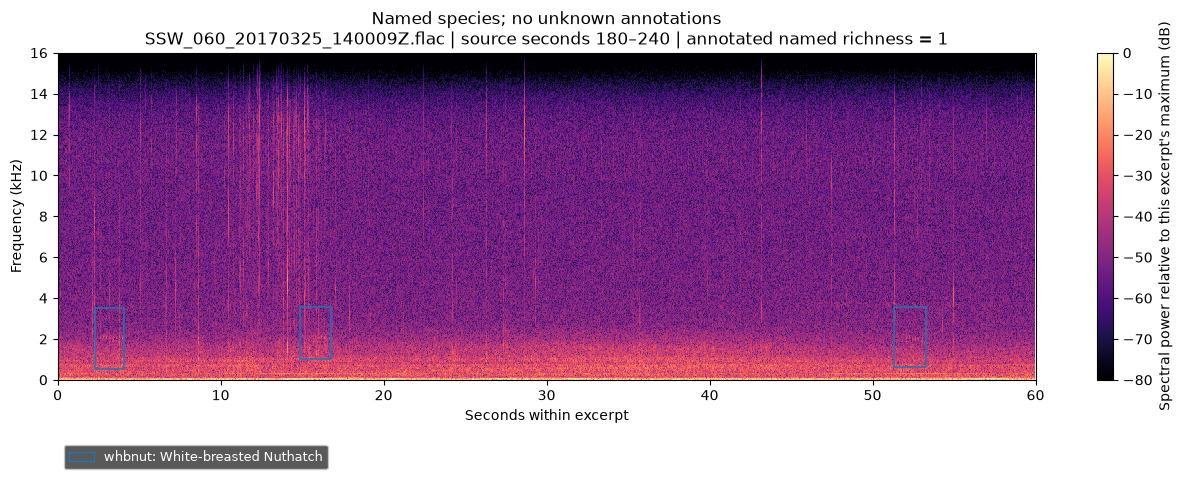

Playback is not amplitude-normalized; quiet audio is expected.


Overlapping annotation boxes: 3
Invalid-frequency boxes omitted from drawing: 0
Zero-duration points flagged: 0



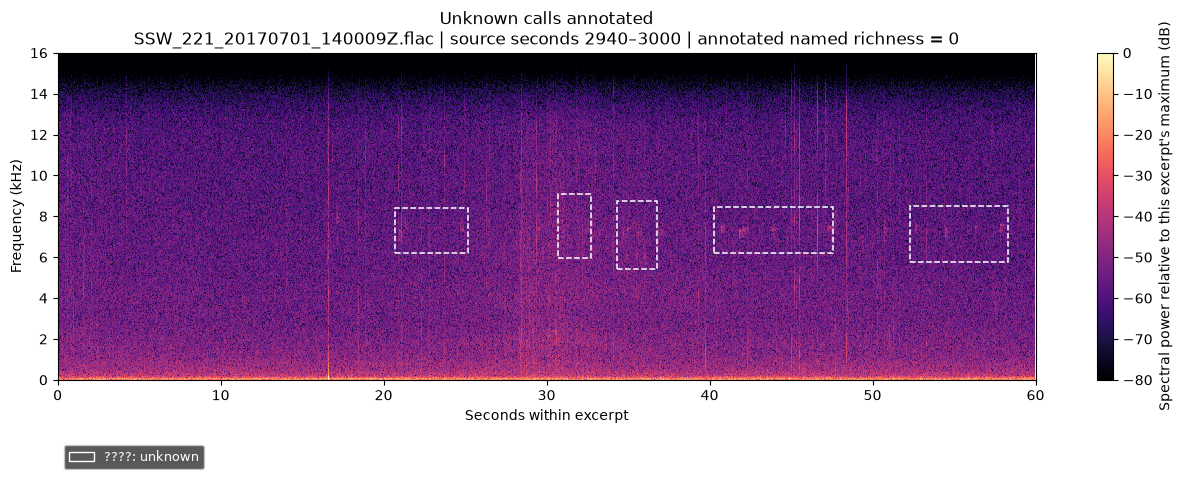

Playback is not amplitude-normalized; quiet audio is expected.


Overlapping annotation boxes: 5
Invalid-frequency boxes omitted from drawing: 0
Zero-duration points flagged: 0



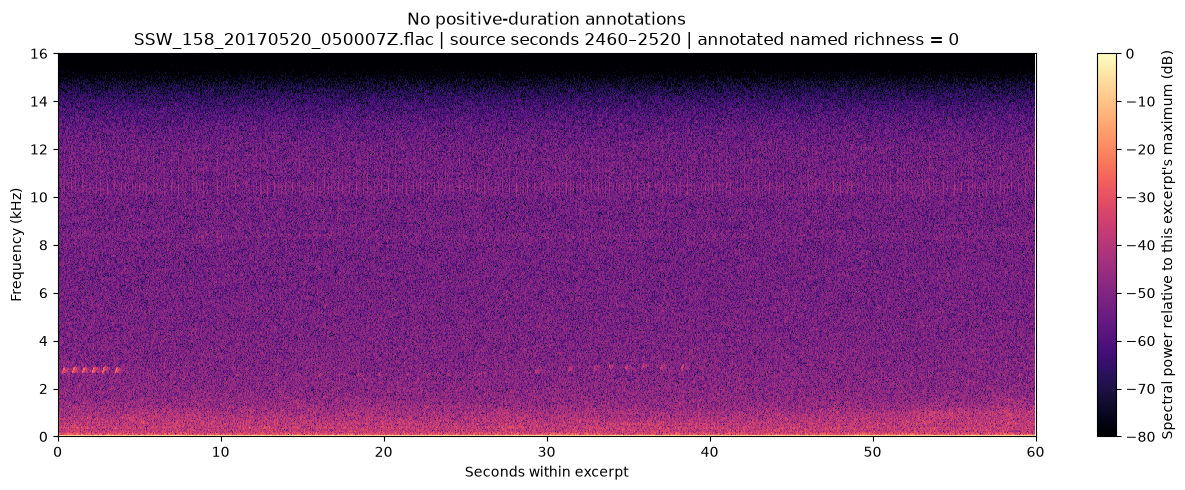

Playback is not amplitude-normalized; quiet audio is expected.


Overlapping annotation boxes: 0
Invalid-frequency boxes omitted from drawing: 0
Zero-duration points flagged: 0

Saved: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\biodiversity\ssw_pilot_20261030T225429974265Z\annotation_alignment_review
Spectrogram colors are relative within each excerpt.
No species labels verified or changed; no models run.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from scipy.signal import spectrogram
import soundfile as sf
from IPython.display import Audio, display

review_dir = pilot_dir / "annotation_alignment_review"
review_dir.mkdir(exist_ok=True)

ref = pd.read_csv(pilot_dir / "pilot_interval_reference.csv")
labels = pd.read_csv(metadata_dir / "annotations.csv")
lookup = pd.read_csv(metadata_dir / "species.csv")
code_col = "Species eBird Code"
common_names = lookup.set_index(code_col)["Common Name"].to_dict()

for column in [
    "Start Time (s)", "End Time (s)",
    "Low Freq (Hz)", "High Freq (Hz)"
]:
    labels[column] = pd.to_numeric(labels[column], errors="raise")

# Use numeric counts to avoid interpreting CSV boolean strings.
categories = {
    "Named species; no unknown annotations": (
        ref["annotated_named_richness"].gt(0)
        & ref["unknown_annotation_boxes"].eq(0)
    ),
    "Unknown calls annotated": ref["unknown_annotation_boxes"].gt(0),
    "No positive-duration annotations": (
        ref["named_annotation_boxes"].eq(0)
        & ref["unknown_annotation_boxes"].eq(0)
    )
}

rng = np.random.default_rng(42)
chosen = []

for category, mask in categories.items():
    candidates = ref.loc[mask].sort_values("interval_id").reset_index(drop=True)
    if candidates.empty:
        print("No example available:", category)
        continue
    row = candidates.iloc[int(rng.integers(len(candidates)))].to_dict()
    row["review_category"] = category
    row["candidate_intervals"] = len(candidates)
    chosen.append(row)

review_manifest = pd.DataFrame(chosen)
review_manifest.to_csv(review_dir / "review_manifest.csv", index=False)

for row in chosen:
    filename = row["Filename"]
    start = float(row["start_seconds"])
    end = float(row["end_seconds"])
    interval_id = row["interval_id"]

    with sf.SoundFile(audio_dir / filename) as recording:
        sr = recording.samplerate
        recording.seek(round(start * sr))
        waveform = recording.read(round((end - start) * sr), dtype="float32")
    assert len(waveform) == round((end - start) * sr)
    assert np.isfinite(waveform).all()

    boxes = labels.loc[
        labels["Filename"].eq(filename)
        & labels["End Time (s)"].gt(labels["Start Time (s)"])
        & labels["Start Time (s)"].lt(end)
        & labels["End Time (s)"].gt(start)
    ].copy()

    frequencies, times, power = spectrogram(
        waveform, fs=sr, window="hann",
        nperseg=1024, noverlap=768,
        detrend=False, scaling="density", mode="psd"
    )
    peak_power = max(float(power.max()), np.finfo(float).tiny)
    relative_db = 10 * np.log10(
        np.maximum(power / peak_power, 1e-10)
    )

    codes = sorted(boxes[code_col].unique())
    colors = {
        code: ("#ffffff" if code == "????"
               else plt.get_cmap("tab20")(i % 20))
        for i, code in enumerate(codes)
    }

    fig, ax = plt.subplots(figsize=(13, 5))
    mesh = ax.pcolormesh(
        times, frequencies / 1000, relative_db,
        shading="auto", cmap="magma", vmin=-80, vmax=0
    )
    skipped_frequency_boxes = 0

    for box in boxes.to_dict("records"):
        left = max(start, box["Start Time (s)"]) - start
        right = min(end, box["End Time (s)"]) - start
        low = box["Low Freq (Hz)"] / 1000
        high = box["High Freq (Hz)"] / 1000

        if high <= low:
            skipped_frequency_boxes += 1
            continue

        ax.add_patch(Rectangle(
            (left, low), right - left, high - low,
            fill=False, edgecolor=colors[box[code_col]],
            linewidth=1.1,
            linestyle="--" if box[code_col] == "????" else "-"
        ))

    ax.set(
        xlim=(0, end - start), ylim=(0, sr / 2000),
        xlabel="Seconds within excerpt",
        ylabel="Frequency (kHz)",
        title=(
            f"{row['review_category']}\n"
            f"{filename} | source seconds {start:.0f}–{end:.0f} | "
            f"annotated named richness = {row['annotated_named_richness']}"
        )
    )
    fig.colorbar(
        mesh, ax=ax,
        label="Spectral power relative to this excerpt's maximum (dB)"
    )

    if codes:
        ax.legend(
            handles=[
                Patch(
                    facecolor="none", edgecolor=colors[code],
                    label=f"{code}: {common_names.get(code, code)}"
                )
                for code in codes
            ],
            loc="upper left", bbox_to_anchor=(0, -0.18),
            ncol=2, facecolor="#303030", labelcolor="white",
            fontsize=9
        )

    fig.tight_layout()
    fig.savefig(
        review_dir / f"{interval_id}.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

    # Export an exact-length excerpt; no gain adjustment or resampling.
    excerpt_path = review_dir / f"{interval_id}.wav"
    sf.write(excerpt_path, waveform, sr, subtype="PCM_16")

    print("Playback is not amplitude-normalized; quiet audio is expected.")
    display(Audio(waveform, rate=sr, normalize=False))

    print("Overlapping annotation boxes:", len(boxes))
    print("Invalid-frequency boxes omitted from drawing:",
          skipped_frequency_boxes)
    print("Zero-duration points flagged:",
          row["zero_duration_points"])
    print()

print("Saved:", review_dir)
print("Spectrogram colors are relative within each excerpt.")
print("No species labels verified or changed; no models run.")

In [11]:
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display

print("1. PLAYBACK CHECK — press Play on this short test tone.")
tone_sr = 16000
t = np.arange(tone_sr // 2) / tone_sr
tone = 0.05 * np.sin(2 * np.pi * 440 * t)
tone *= np.hanning(len(tone))
display(Audio(tone, rate=tone_sr, normalize=False))

review_manifest = pd.read_csv(review_dir / "review_manifest.csv")

print("\n2. AMPLIFIED EXCERPTS — start with a moderate device volume.")

for row in review_manifest.to_dict("records"):
    path = review_dir / f"{row['interval_id']}.wav"
    waveform, sr = sf.read(path, dtype="float64")

    assert np.isfinite(waveform).all()
    peak = float(np.max(np.abs(waveform)))
    rms = float(np.sqrt(np.mean(waveform**2)))

    print(f"\n{row['review_category']}")
    print(path.name)
    print(f"Duration: {len(waveform) / sr:.1f} s")
    print(f"Peak: {peak:.6f}; RMS: {rms:.6f}")

    if peak == 0:
        print("This exported excerpt is digitally silent. Inspect extraction.")
        continue

    print(f"RMS level: {20 * np.log10(max(rms, 1e-15)):.1f} dBFS")

    # Listening aid: target peak 0.8, limiting amplification to 40 dB.
    gain = min(100.0, 0.8 / peak)
    playback = waveform * gain
    assert np.max(np.abs(playback)) <= 0.800001

    print(f"Playback gain: {20 * np.log10(gain):+.1f} dB")
    display(Audio(playback, rate=sr, normalize=False))

print("\nAmplification is for listening only; no files were modified.")
print("It also amplifies background noise—not just bird calls.")

1. PLAYBACK CHECK — press Play on this short test tone.



2. AMPLIFIED EXCERPTS — start with a moderate device volume.

Named species; no unknown annotations
SSW_060_20170325_140009Z_m03.wav
Duration: 60.0 s
Peak: 0.082428; RMS: 0.005714
RMS level: -44.9 dBFS
Playback gain: +19.7 dB



Unknown calls annotated
SSW_221_20170701_140009Z_m49.wav
Duration: 60.0 s
Peak: 0.118225; RMS: 0.003909
RMS level: -48.2 dBFS
Playback gain: +16.6 dB



No positive-duration annotations
SSW_158_20170520_050007Z_m41.wav
Duration: 60.0 s
Peak: 0.014557; RMS: 0.007074
RMS level: -43.0 dBFS
Playback gain: +34.8 dB



Amplification is for listening only; no files were modified.
It also amplifies background noise—not just bird calls.


In [12]:
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display

review = pd.read_csv(review_dir / "review_manifest.csv")
row = review.loc[
    review["review_category"].eq("Named species; no unknown annotations")
].iloc[0]

with sf.SoundFile(audio_dir / row["Filename"]) as recording:
    sr = recording.samplerate
    recording.seek(round(float(row["start_seconds"]) * sr))
    signal = recording.read(
        round(60 * sr), dtype="float64", always_2d=True
    )

assert signal.shape[0] == 60 * sr
assert np.isfinite(signal).all()
mono = signal.mean(axis=1)
peak = float(np.max(np.abs(mono)))
rms = float(np.sqrt(np.mean(mono**2)))

print("File:", row["Filename"])
print("Source start (seconds):", row["start_seconds"])
print("Sample rate:", sr)
print(f"Peak: {peak:.8f}")
print(f"RMS: {rms:.8f}")

if peak == 0:
    print("The source excerpt contains only digital zeros.")
else:
    print("Press Play below. Start with a LOW device volume.")
    print("Playback is normalized; source audio remains unchanged.")
    display(Audio(mono, rate=sr, normalize=True))

File: SSW_060_20170325_140009Z.flac
Source start (seconds): 180
Sample rate: 32000
Peak: 0.08242798
RMS: 0.00571368
Press Play below. Start with a LOW device volume.
Playback is normalized; source audio remains unchanged.


In [13]:
for row in pd.read_csv(
    review_dir / "review_manifest.csv"
).to_dict("records"):
    signal, sr = sf.read(
        review_dir / f"{row['interval_id']}.wav"
    )
    print(row["review_category"])
    display(Audio(signal, rate=sr, normalize=True))

Named species; no unknown annotations


Unknown calls annotated


No positive-duration annotations


Source annotation: White-breasted Nuthatch (whbnut)
Original annotation: 182.30–184.10 s
Playback crop: 178.20–188.20 s


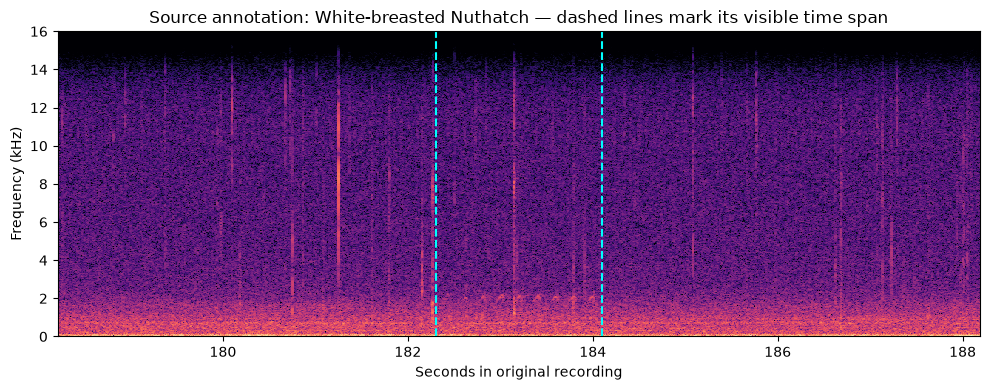

Normalized listening only; begin at low device volume.


In [14]:
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import spectrogram
from IPython.display import Audio, display

review = pd.read_csv(review_dir / "review_manifest.csv")
example = review.loc[
    review["review_category"].eq("Named species; no unknown annotations")
].iloc[0]

labels = pd.read_csv(metadata_dir / "annotations.csv")
lookup = pd.read_csv(metadata_dir / "species.csv")

start_col = "Start Time (s)"
end_col = "End Time (s)"
code_col = "Species eBird Code"

for col in [start_col, end_col, "Low Freq (Hz)", "High Freq (Hz)"]:
    labels[col] = pd.to_numeric(labels[col], errors="raise")

candidates = labels.loc[
    labels["Filename"].eq(example["Filename"])
    & labels[code_col].ne("????")
    & labels[end_col].gt(labels[start_col])
    & labels[start_col].lt(example["end_seconds"])
    & labels[end_col].gt(example["start_seconds"])
].sort_values([start_col, end_col, code_col])

assert not candidates.empty

# Deterministic choice: earliest overlapping named annotation.
box = candidates.iloc[0]
overlap_start = max(float(box[start_col]), float(example["start_seconds"]))
overlap_end = min(float(box[end_col]), float(example["end_seconds"]))
center = (overlap_start + overlap_end) / 2

crop_start = max(0, center - 5)
crop_end = min(3600, center + 5)

with sf.SoundFile(audio_dir / example["Filename"]) as recording:
    sr = recording.samplerate
    recording.seek(round(crop_start * sr))
    signal = recording.read(
        round((crop_end - crop_start) * sr), dtype="float64"
    )

name = lookup.set_index(code_col).loc[box[code_col], "Common Name"]
print("Source annotation:", name, f"({box[code_col]})")
print(f"Original annotation: {box[start_col]:.2f}–{box[end_col]:.2f} s")
print(f"Playback crop: {crop_start:.2f}–{crop_end:.2f} s")

freq, time, power = spectrogram(
    signal, fs=sr, nperseg=1024, noverlap=768, detrend=False
)
relative_db = 10 * np.log10(
    np.maximum(power / max(power.max(), 1e-30), 1e-10)
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.pcolormesh(
    time + crop_start, freq / 1000, relative_db,
    shading="auto", cmap="magma", vmin=-70, vmax=0
)
left = max(crop_start, float(box[start_col]))
right = min(crop_end, float(box[end_col]))
ax.axvline(left, color="cyan", linestyle="--")
ax.axvline(right, color="cyan", linestyle="--")
ax.set(
    xlabel="Seconds in original recording",
    ylabel="Frequency (kHz)",
    title=f"Source annotation: {name} — dashed lines mark its visible time span",
    ylim=(0, sr / 2000)
)
plt.tight_layout()
plt.show()

print("Normalized listening only; begin at low device volume.")
display(Audio(signal, rate=sr, normalize=True))

In [15]:
import sys
import platform
import shutil
from importlib import metadata

print("Python executable:", sys.executable)
print("Python version:", platform.python_version())
print("Platform:", platform.platform())
print("FFmpeg executable:", shutil.which("ffmpeg"))

for package in [
    "birdnet-analyzer",
    "tensorflow",
    "tflite-runtime",
    "numpy",
    "soundfile"
]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed")

Python executable: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\venv\Scripts\python.exe
Python version: 3.11.9
Platform: Windows-10-10.0.26200-SP0
FFmpeg executable: None
birdnet-analyzer: not installed
tensorflow: not installed
tflite-runtime: not installed
numpy: 2.4.6
soundfile: 0.14.0


In [17]:
import os
import sys
import subprocess

# Apply only to BirdNET subprocesses—not the notebook kernel.
birdnet_process_env = os.environ.copy()
birdnet_process_env["MPLBACKEND"] = "Agg"

check_script = """
import sys
from importlib.metadata import version
import matplotlib
import tensorflow as tf
import soundfile as sf

print("Inference Python:", sys.executable)
print("Plotting backend:", matplotlib.get_backend())
for package in ["birdnet-analyzer", "tensorflow", "numpy", "soundfile"]:
    print(f"{package}: {version(package)}")
print("TensorFlow calculation:", tf.reduce_sum(tf.constant([1., 2.])).numpy())
print("FLAC decoding available:", "FLAC" in sf.available_formats())
"""

result = subprocess.run(
    [str(birdnet_python), "-c", check_script],
    env=birdnet_process_env,
    capture_output=True,
    text=True
)

(setup_dir / "runtime_check_agg.log").write_text(
    result.stdout + "\n" + result.stderr,
    encoding="utf-8"
)
print(result.stdout)

if result.returncode:
    print(result.stderr[-6000:])
    raise RuntimeError("Runtime check failed; see output above.")

print("Runtime check: PASS")
print("Research kernel unchanged:", sys.executable)
print("No audio inference performed.")

Inference Python: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\.venv-birdnet\Scripts\python.exe
Plotting backend: Agg
birdnet-analyzer: 2.4.0
tensorflow: 2.21.0
numpy: 2.4.6
soundfile: 0.14.0
TensorFlow calculation: 3.0
FLAC decoding available: True

Runtime check: PASS
Research kernel unchanged: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\venv\Scripts\python.exe
No audio inference performed.


In [18]:
import json
import subprocess

inventory_script = """
import json
import hashlib
from pathlib import Path
from importlib.metadata import version
import tensorflow as tf
import birdnet_analyzer.config as cfg

def inspect_file(setting):
    path = Path(getattr(cfg, setting))
    result = {
        "setting": setting,
        "path": str(path),
        "exists": path.is_file()
    }
    if path.is_file():
        sha = hashlib.sha256()
        with path.open("rb") as handle:
            while chunk := handle.read(1024**2):
                sha.update(chunk)
        result["bytes"] = path.stat().st_size
        result["sha256"] = sha.hexdigest()
        if setting == "BIRDNET_LABELS_FILE":
            result["label_count"] = len(
                path.read_text(encoding="utf-8").splitlines()
            )
    return result

inventory = {
    "package_version": version("birdnet-analyzer"),
    "configured_model_version": cfg.MODEL_VERSION,
    "model_sample_rate": cfg.BIRDNET_SAMPLE_RATE,
    "segment_seconds": cfg.BIRDNET_SIG_LENGTH,
    "tensorflow_lite_interpreter_available": hasattr(tf.lite, "Interpreter"),
    "files": [
        inspect_file(setting)
        for setting in [
            "BIRDNET_MODEL_PATH",
            "BIRDNET_LABELS_FILE",
            "MDATA_MODEL_PATH",
            "CODES_FILE"
        ]
    ]
}
print(json.dumps(inventory, indent=2))
"""

result = subprocess.run(
    [str(birdnet_python), "-c", inventory_script],
    env=birdnet_process_env,
    capture_output=True,
    text=True
)
(setup_dir / "model_inventory_stderr.log").write_text(
    result.stderr, encoding="utf-8"
)

if result.returncode:
    print(result.stderr[-6000:])
    raise RuntimeError("Model inventory failed.")

model_inventory = json.loads(result.stdout)
(setup_dir / "model_inventory.json").write_text(
    json.dumps(model_inventory, indent=2), encoding="utf-8"
)
print(json.dumps(model_inventory, indent=2))
print("\nNo downloads or audio inference performed.")

{
  "package_version": "2.4.0",
  "configured_model_version": "V2.4",
  "model_sample_rate": 48000,
  "segment_seconds": 3.0,
  "tensorflow_lite_interpreter_available": true,
  "files": [
    {
      "setting": "BIRDNET_MODEL_PATH",
      "path": "c:\\Users\\Samanwita\\Downloads\\from-soundscapes-to-biodiversity\\.venv-birdnet\\Lib\\site-packages\\birdnet_analyzer\\checkpoints\\V2.4\\BirdNET_GLOBAL_6K_V2.4_Model_FP32.tflite",
      "exists": false
    },
    {
      "setting": "BIRDNET_LABELS_FILE",
      "path": "c:\\Users\\Samanwita\\Downloads\\from-soundscapes-to-biodiversity\\.venv-birdnet\\Lib\\site-packages\\birdnet_analyzer\\checkpoints\\V2.4\\BirdNET_GLOBAL_6K_V2.4_Labels.txt",
      "exists": false
    },
    {
      "setting": "MDATA_MODEL_PATH",
      "path": "c:\\Users\\Samanwita\\Downloads\\from-soundscapes-to-biodiversity\\.venv-birdnet\\Lib\\site-packages\\birdnet_analyzer\\checkpoints\\V2.4\\BirdNET_GLOBAL_6K_V2.4_MData_Model_V2_FP16.tflite",
      "exists": false
    }

In [19]:
import json
import subprocess

download_script = """
from birdnet_analyzer import utils

utils.ensure_model_exists()
assert utils.check_birdnet_files(), "Model bundle incomplete."
print("Official V2.4 model bundle: present")
"""

log_path = setup_dir / "model_download.log"
print("Downloading/checking the official model bundle.")
print("This may take several minutes. Log:", log_path, flush=True)

with log_path.open("w", encoding="utf-8") as log:
    result = subprocess.run(
        [str(birdnet_python), "-u", "-c", download_script],
        env=birdnet_process_env,
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True
    )

if result.returncode:
    print(log_path.read_text(encoding="utf-8")[-6000:])
    raise RuntimeError("Model setup failed; see log above.")

# Reuse the inventory script from the preceding cell.
result = subprocess.run(
    [str(birdnet_python), "-c", inventory_script],
    env=birdnet_process_env,
    capture_output=True,
    text=True
)

(setup_dir / "model_inventory_after_download_stderr.log").write_text(
    result.stderr, encoding="utf-8"
)
if result.returncode:
    print(result.stderr[-6000:])
    raise RuntimeError("Post-download inventory failed.")

model_inventory = json.loads(result.stdout)
assert all(item["exists"] for item in model_inventory["files"])

(setup_dir / "model_inventory_after_download.json").write_text(
    json.dumps(model_inventory, indent=2), encoding="utf-8"
)

print(json.dumps(model_inventory, indent=2))
print("\nModel files present; SHA-256 fingerprints recorded.")
print("Hashes document downloaded files; they are not independent publisher verification.")
print("No audio inference performed. Research environment unchanged.")

Downloading/checking the official model bundle.
This may take several minutes. Log: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\biodiversity\ssw_pilot_20261030T225429974265Z\birdnet_setup\model_download.log
{
  "package_version": "2.4.0",
  "configured_model_version": "V2.4",
  "model_sample_rate": 48000,
  "segment_seconds": 3.0,
  "tensorflow_lite_interpreter_available": true,
  "files": [
    {
      "setting": "BIRDNET_MODEL_PATH",
      "path": "c:\\Users\\Samanwita\\Downloads\\from-soundscapes-to-biodiversity\\.venv-birdnet\\Lib\\site-packages\\birdnet_analyzer\\checkpoints\\V2.4\\BirdNET_GLOBAL_6K_V2.4_Model_FP32.tflite",
      "exists": true,
      "bytes": 51726412,
      "sha256": "55f3e4055b1a13bfa9a2452731d0d34f6a02d6b775a334362665892794165e4c"
    },
    {
      "setting": "BIRDNET_LABELS_FILE",
      "path": "c:\\Users\\Samanwita\\Downloads\\from-soundscapes-to-biodiversity\\.venv-birdnet\\Lib\\site-packages\\birdnet_analyzer\\checkpoints\

In [20]:
import json
import subprocess
from datetime import datetime, timezone
import pandas as pd

pilot = pd.read_csv(pilot_dir / "pilot_manifest.csv")
first_filename = pilot.iloc[0]["Filename"]
input_audio = audio_dir / first_filename
assert input_audio.is_file()

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
inference_dir = pilot_dir / f"birdnet_first_recording_{stamp}"
inference_dir.mkdir(exist_ok=False)

command = [
    str(birdnet_python), "-u", "-m", "birdnet_analyzer.analyze",
    str(input_audio),
    "-o", str(inference_dir),
    "--lat", "-1",
    "--lon", "-1",
    "--week", "-1",
    "--min_conf", "0.01",
    "--sensitivity", "1.0",
    "--overlap", "0",
    "--merge_consecutive", "1",
    "--audio_speed", "1.0",
    "--fmin", "0",
    "--fmax", "15000",
    "--threads", "2",
    "--batch_size", "1",
    "--rtype", "csv",
    "--additional_columns",
    "lat", "lon", "week", "overlap", "sensitivity",
    "min_conf", "species_list", "model"
]

protocol = {
    "purpose": "First-recording engineering inference",
    "input_file": str(input_audio),
    "selection": "First row of the previously fixed pilot manifest",
    "package_version": "2.4.0",
    "model_version": "V2.4",
    "model_inventory": model_inventory,
    "output_score_floor": 0.01,
    "location_date_filter": False,
    "custom_species_list": None,
    "overlap_seconds": 0,
    "consecutive_detections_merged": False,
    "external_amplification": False,
    "evaluation_threshold_selected": False,
    "command": command
}
(inference_dir / "run_protocol.json").write_text(
    json.dumps(protocol, indent=2), encoding="utf-8"
)

log_path = inference_dir / "inference.log"
print("Analyzing:", first_filename, flush=True)
print("Progress log:", log_path, flush=True)

with log_path.open("w", encoding="utf-8") as log:
    result = subprocess.run(
        command,
        env=birdnet_process_env,
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True
    )

protocol["returncode"] = result.returncode
protocol["finished_utc"] = datetime.now(timezone.utc).isoformat()
(inference_dir / "run_protocol.json").write_text(
    json.dumps(protocol, indent=2), encoding="utf-8"
)

log_text = log_path.read_text(encoding="utf-8", errors="replace")
print("\nLOG END")
print(log_text[-5000:])

if result.returncode:
    raise RuntimeError("Inference failed; inspect the log before continuing.")

csv_files = sorted(inference_dir.rglob("*.csv"))
assert csv_files, "No CSV output found; inspect inference.log."

print("\nOUTPUT TABLES")
for path in csv_files:
    table = pd.read_csv(path)
    print("\nFile:", path.relative_to(inference_dir))
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())
    print(table.head(3).to_string(index=False))

print("\nSaved:", inference_dir)
print("Outputs require validation before biological interpretation.")

Analyzing: SSW_002_20170225_020001Z.flac
Progress log: c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\biodiversity\ssw_pilot_20261030T225429974265Z\birdnet_first_recording_20261031T000153310112Z\inference.log

LOG END
I0000 00:00:1793404916.153757   23320 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793404920.139529   23320 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
Model found!
Found 1 files to analyze
Species list contains 6522 species
Analyzing c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\raw\external\sapsucker_woods_7079380\aud

In [21]:
import numpy as np
import pandas as pd

result_files = list(inference_dir.glob("*.BirdNET.results.csv"))
assert len(result_files) == 1
detections = pd.read_csv(result_files[0])

numeric_columns = [
    "Start (s)", "End (s)", "Confidence",
    "lat", "lon", "week", "overlap", "sensitivity", "min_conf"
]
for column in numeric_columns:
    detections[column] = pd.to_numeric(detections[column], errors="raise")

assert np.isfinite(detections[numeric_columns].to_numpy()).all()
assert detections["Confidence"].between(0, 1).all()
assert detections["Start (s)"].ge(0).all()
assert detections["End (s)"].le(3600).all()
assert np.allclose(
    detections["End (s)"] - detections["Start (s)"], 3
)
assert np.allclose(
    detections["Start (s)"] / 3,
    np.round(detections["Start (s)"] / 3)
)
assert detections["lat"].eq(-1).all()
assert detections["lon"].eq(-1).all()
assert detections["week"].eq(-1).all()
assert detections["overlap"].eq(0).all()
assert detections["sensitivity"].eq(1).all()
assert np.allclose(detections["min_conf"], 0.01)
assert detections["species_list"].fillna("").eq("").all()
assert detections["model"].eq(
    "BirdNET_GLOBAL_6K_V2.4_Model_FP32.tflite"
).all()

duplicate_count = detections.duplicated(
    ["Start (s)", "End (s)", "Scientific name", "Common name"]
).sum()
assert duplicate_count == 0

print("OUTPUT STRUCTURE AND RECORDED SETTINGS: PASS")
print("Candidate rows:", len(detections))
print(
    "Windows with at least one saved candidate:",
    detections[["Start (s)", "End (s)"]].drop_duplicates().shape[0],
    "/ 1200 expected analysis windows"
)
print(
    "A window without a saved row may have no score above 0.01; "
    "the thresholded CSV alone cannot verify its processing."
)

# Exact-name matching is an initial audit, not a finalized taxonomy crosswalk.
lookup = pd.read_csv(metadata_dir / "species.csv")
named_lookup = lookup.loc[
    lookup["Species eBird Code"].ne("????")
].copy()

assert named_lookup["Scientific Name"].is_unique
name_to_code = named_lookup.set_index(
    "Scientific Name"
)["Species eBird Code"]

detections["reference_code_exact_match"] = (
    detections["Scientific name"].map(name_to_code)
)

label_audit = (
    detections.groupby(
        ["Scientific name", "Common name"], dropna=False
    )
    .agg(
        candidate_rows=("Confidence", "size"),
        maximum_score=("Confidence", "max"),
        rows_ge_0_5=("Confidence", lambda x: int(x.ge(0.5).sum()))
    )
    .reset_index()
)
label_audit["reference_code_exact_match"] = (
    label_audit["Scientific name"].map(name_to_code)
)
label_audit = label_audit.sort_values(
    ["maximum_score", "Scientific name"], ascending=[False, True]
)

print("\nHIGHEST-SCORING OUTPUT LABELS")
print(label_audit.head(20).to_string(index=False))

unmatched = label_audit.loc[
    label_audit["reference_code_exact_match"].isna()
]
print("\nLABELS WITHOUT AN EXACT NAME MATCH IN THE DATASET LOOKUP")
print(unmatched.head(30).to_string(index=False))
print("Total unmatched labels:", len(unmatched))
print(
    "Unmatched may mean a species outside the dataset, a taxonomy "
    "difference, or a non-bird class—not necessarily an invalid prediction."
)

# Summarize output sensitivity without selecting an evaluation threshold.
threshold_rows = []
for threshold in [0.01, 0.1, 0.25, 0.5, 0.75, 0.9]:
    selected = detections.loc[detections["Confidence"].ge(threshold)]
    threshold_rows.append({
        "score_threshold": threshold,
        "candidate_rows": len(selected),
        "distinct_output_labels": selected[
            ["Scientific name", "Common name"]
        ].drop_duplicates().shape[0],
        "windows_with_candidates": selected[
            ["Start (s)", "End (s)"]
        ].drop_duplicates().shape[0]
    })

threshold_audit = pd.DataFrame(threshold_rows)
print("\nOUTPUT COUNTS BY SCORE THRESHOLD — NOT BIRD RICHNESS")
print(threshold_audit.to_string(index=False))

# Reference labels for this recording, retaining unknowns in the report.
annotations = pd.read_csv(metadata_dir / "annotations.csv")
reference_support = (
    annotations.loc[annotations["Filename"].eq(first_filename)]
    .groupby("Species eBird Code")
    .size().rename("annotation_boxes").reset_index()
    .merge(lookup, on="Species eBird Code", how="left", validate="one_to_one")
)
print("\nEXPERT ANNOTATION LABELS FOR THIS RECORDING")
print(reference_support.to_string(index=False))

label_audit.to_csv(inference_dir / "output_label_audit.csv", index=False)
threshold_audit.to_csv(
    inference_dir / "output_threshold_counts.csv", index=False
)
reference_support.to_csv(
    inference_dir / "recording_reference_labels.csv", index=False
)

print("\nNo predictions removed, thresholds selected, or models rerun.")

OUTPUT STRUCTURE AND RECORDED SETTINGS: PASS
Candidate rows: 10655
Windows with at least one saved candidate: 1200 / 1200 expected analysis windows
A window without a saved row may have no score above 0.01; the thresholded CSV alone cannot verify its processing.

HIGHEST-SCORING OUTPUT LABELS
      Scientific name             Common name  candidate_rows  maximum_score  rows_ge_0_5 reference_code_exact_match
    Corvus ossifragus               Fish Crow              20         0.7963            1                        NaN
   Quiscalus quiscula          Common Grackle             754         0.6360            1                     comgra
Corvus brachyrhynchos           American Crow            1159         0.6269            1                     amecro
 Anser brachyrhynchus       Pink-footed Goose               7         0.5394            1                        NaN
          Fulica atra           Eurasian Coot              10         0.4778            0                        NaN
    